<a href="https://colab.research.google.com/github/atman500/atman500/blob/main/Hirarical_Full_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
from google.colab import files

In [3]:
upload=files.upload()

Saving hierarchical_model_dataset_500.csv to hierarchical_model_dataset_500.csv


In [5]:
df=pd.read_csv("hierarchical_model_dataset_500.csv",sep=";")
print(df.head())

  Employee_ID Department_ID  Training_Hours  Experience_Years  \
0        E001           D01             9.0               6.4   
1        E002           D01            23.6              11.8   
2        E003           D01            15.4               3.4   
3        E004           D01            25.6               7.0   
4        E005           D01            30.3               5.2   

   Workload_Hours_Per_Week  Job_Satisfaction  Performance_Score  
0                     46.7              7.16              79.06  
1                     44.1              7.38              91.25  
2                     31.5              5.68              68.92  
3                     47.8              6.77              82.74  
4                     41.3              6.12              83.37  


In [6]:
df.describe()

,Training_Hours,Experience_Years,Workload_Hours_Per_Week,Job_Satisfaction,Performance_Score
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,21.708600,7.560600,39.858200,7.210280,81.429100
std,6.489871,4.743909,6.086145,1.031601,9.275473
min,3.100000,0.500000,20.000000,4.450000,56.620000
25%,17.375000,4.075000,35.600000,6.537500,75.087500
50%,21.800000,6.600000,39.650000,7.215000,81.840000
75%,26.300000,9.900000,44.325000,7.902500,88.402500
max,40.700000,25.000000,59.800000,10.000000,100.000000


In [7]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

# **Isolate the clustering features:**

In [12]:
# Set Employee_ID as the index
df_clustering = df.set_index('Employee_ID')

# Drop Department_ID to leave only numerical features for the model
features = df_clustering.drop(columns=['Department_ID'])
features.head()

,Training_Hours,Experience_Years,Workload_Hours_Per_Week,Job_Satisfaction,Performance_Score,Cluster_Label
Employee_ID,,,,,,
E001,9.0,6.4,46.7,7.16,79.06,1
E002,23.6,11.8,44.1,7.38,91.25,0
E003,15.4,3.4,31.5,5.68,68.92,1
E004,25.6,7.0,47.8,6.77,82.74,0
E005,30.3,5.2,41.3,6.12,83.37,1


### **2.Standardize the numerical scales:**

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)
scaled_features

array([[-1.96018197, -0.24489556,  1.12528581, -0.04878857, -0.25567134,
        -0.0304942 ],
       [ 0.29173065,  0.89454611,  0.69765813,  0.16468567,  1.05986351,
        -1.30108582],
       [-0.97304219, -0.8779187 , -1.37469144, -1.48488799, -1.34997186,
        -0.0304942 ],
       ...,
       [-0.03217459, -0.60360867,  1.0266025 , -1.78569259, -1.86150879,
        -0.0304942 ],
       [ 1.77244032, -0.92012025,  1.12528581,  0.44608353, -0.141277  ,
        -1.30108582],
       [ 2.43567486,  0.59913531, -0.38785831,  0.20349917,  1.523916  ,
        -1.30108582]], shape=(500, 6))

# **3.Plot the Dendrogram:**

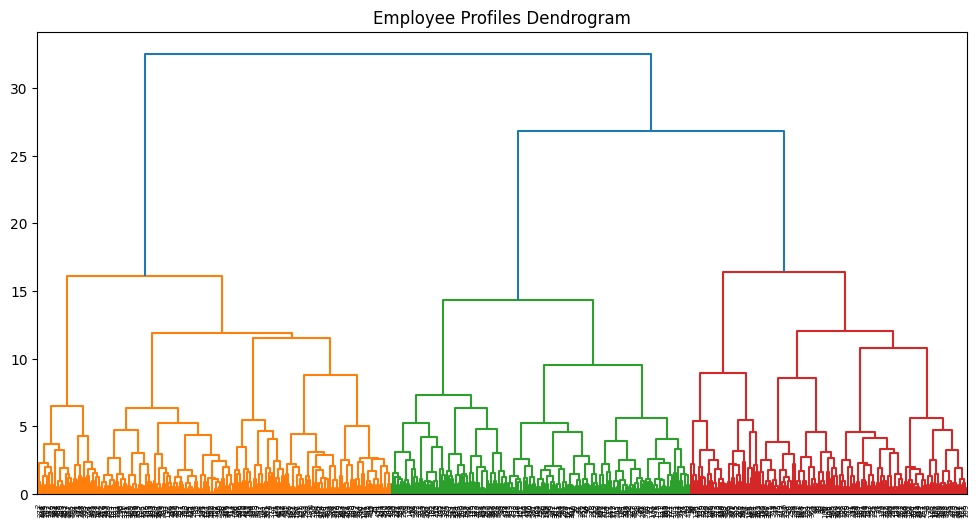

In [10]:
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.title("Employee Profiles Dendrogram")

# Create the dendrogram using the scaled data
dendrogram = sch.dendrogram(sch.linkage(scaled_features, method='ward'))
plt.show()

# **4.Apply Agglomerative Clustering:**

In [11]:
from sklearn.cluster import AgglomerativeClustering

# Train the model (replace 3 with the number of clusters you see in the dendrogram)
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')

# Assign the resulting clusters back to your main dataframe
df['Cluster_Label'] = hc.fit_predict(scaled_features)

# View the average stats for each employee cluster
print(df.groupby('Cluster_Label')[['Training_Hours', 'Experience_Years', 'Workload_Hours_Per_Week', 'Job_Satisfaction', 'Performance_Score']].mean())

               Training_Hours  Experience_Years  Workload_Hours_Per_Week  \
Cluster_Label                                                              
0                   27.886577         11.408725                42.252349   
1                   17.609474          5.846316                42.737895   
2                   20.828571          6.022360                34.244099   

               Job_Satisfaction  Performance_Score  
Cluster_Label                                       
0                      7.532349          88.929597  
1                      6.572895          74.319579  
2                      7.664410          82.877764  


Interpretation

In [15]:
print("""
=========================================
          CLUSTER INTERPRETATION
=========================================

Based on the average metrics of each cluster, we can group the employees into three distinct profiles:

1. Cluster 0: High-Performing Experienced Veterans
   - Highest Training Hours (~27.9 hours)
   - Highest Experience (~11.4 years)
   - High Workload (~42.3 hours/week)
   - High Job Satisfaction (~7.5)
   - Highest Performance Score (~88.9)
   *Interpretation*: These are experienced senior employees who take on significant responsibilities and training. They are highly satisfied and represent the highest performers in the organization.

2. Cluster 1: Highly Loaded, Low-Performing Under-Satisfied Juniors
   - Lowest Training Hours (~17.6 hours)
   - Lowest Experience (~5.8 years)
   - Highest Workload (~42.7 hours/week)
   - Lowest Job Satisfaction (~6.6)
   - Lowest Performance Score (~74.3)
   *Interpretation*: This is a critical group of junior staff. They are facing high workloads with the lowest levels of training and support, resulting in the lowest job satisfaction and lower overall performance scores.

3. Cluster 2: Well-Balanced, Satisfied Core Contributors
   - Moderate Training Hours (~20.8 hours)
   - Moderate/Lower Experience (~6.0 years)
   - Lowest Workload (~34.2 hours/week)
   - Highest Job Satisfaction (~7.7)
   - Strong Performance Score (~82.9)
   *Interpretation*: These employees enjoy the best work-life balance (lowest workload) which directly correlates with their high job satisfaction. They consistently deliver strong, above-average performance.
""")


          CLUSTER INTERPRETATION

Based on the average metrics of each cluster, we can group the employees into three distinct profiles:

1. Cluster 0: High-Performing Experienced Veterans
   - Highest Training Hours (~27.9 hours)
   - Highest Experience (~11.4 years)
   - High Workload (~42.3 hours/week)
   - High Job Satisfaction (~7.5)
   - Highest Performance Score (~88.9)
   *Interpretation*: These are experienced senior employees who take on significant responsibilities and training. They are highly satisfied and represent the highest performers in the organization.

2. Cluster 1: Highly Loaded, Low-Performing Under-Satisfied Juniors
   - Lowest Training Hours (~17.6 hours)
   - Lowest Experience (~5.8 years)
   - Highest Workload (~42.7 hours/week)
   - Lowest Job Satisfaction (~6.6)
   - Lowest Performance Score (~74.3)
   *Interpretation*: This is a critical group of junior staff. They are facing high workloads with the lowest levels of training and support, resulting in the 